In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.numerics import amplification_factor, stability_limit, euler_unclamped, exact_solution
from src.config import BATTERY_SELF_DISCHARGE as K

DT = 1.0   # hours
print(f"Leak rate k = {K} per hour")
print(f"Stability limit 2/k = {stability_limit(K):,.0f} hours ({stability_limit(K)/24:.0f} days)")
print(f"Your step is {DT} hour, so k*dt = {K*DT} and the amplification factor is {amplification_factor(K, DT)}")
print(f"The limit is {stability_limit(K)/DT:,.0f} times larger than your step")

Leak rate k = 0.001 per hour
Stability limit 2/k = 2,000 hours (83 days)
Your step is 1.0 hour, so k*dt = 0.001 and the amplification factor is 0.999
The limit is 2,000 times larger than your step


In [2]:
rows = []
for k in [0.001, 0.5, 1.0, 1.5, 2.0, 2.5]:
    g = amplification_factor(k, DT)
    verdict = "stable" if abs(g) < 1 else ("borderline" if abs(g) == 1 else "UNSTABLE")
    rows.append({"k (per hour)": k, "k x dt": k * DT, "factor g": g, "|g|": abs(g), "verdict": verdict})
pd.DataFrame(rows)

,k (per hour),k x dt,factor g,|g|,verdict
0,0.001,0.001,0.999,0.999,stable
1,0.500,0.500,0.500,0.500,stable
2,1.000,1.000,0.000,0.000,stable
3,1.500,1.500,-0.500,0.500,stable
4,2.000,2.000,-1.000,1.000,borderline
5,2.500,2.500,-1.500,1.500,UNSTABLE


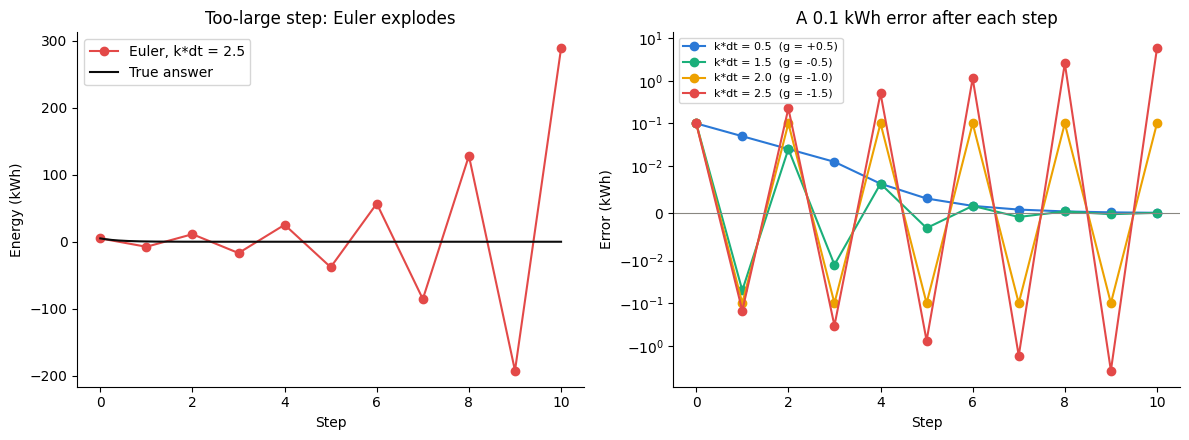

In [3]:
steps = 10
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: the unstable case against the true answer (no charging, no limits)
t = np.arange(steps + 1)
axes[0].plot(t, euler_unclamped(5.0, 2.5, DT, steps), "o-", color="#e34948", label="Euler, k*dt = 2.5")
axes[0].plot(np.linspace(0, steps, 200), exact_solution(5.0, 2.5, np.linspace(0, steps, 200)),
             color="#0b0b0b", label="True answer")
axes[0].set_title("Too-large step: Euler explodes"); axes[0].set_xlabel("Step"); axes[0].set_ylabel("Energy (kWh)")
axes[0].legend()

# Right: size of a 0.1 kWh error for four cases
for k, colour in [(0.5, "#2a78d6"), (1.5, "#1baf7a"), (2.0, "#eda100"), (2.5, "#e34948")]:
    a = euler_unclamped(5.0, k, DT, steps, forcing=2.0)
    b = euler_unclamped(5.1, k, DT, steps, forcing=2.0)
    axes[1].plot(t, b - a, "o-", color=colour, label=f"k*dt = {k*DT}  (g = {amplification_factor(k, DT):+.1f})")
axes[1].set_yscale("symlog", linthresh=0.01)
axes[1].axhline(0, color="#898781", lw=0.8)
axes[1].set_title("A 0.1 kWh error after each step"); axes[1].set_xlabel("Step"); axes[1].set_ylabel("Error (kWh)")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "fig_euler_stability.png", dpi=150)
plt.show()

In [4]:
 n = 24 * 30
perturb = euler_unclamped(5.1, K, DT, n) - euler_unclamped(5.0, K, DT, n)
print(f"A 0.1 kWh error becomes {perturb[-1]:.4f} kWh after 30 days (it shrinks, as predicted)")

e = euler_unclamped(10.0, K, DT, n)
x = exact_solution(10.0, K, n)
print(f"Euler after 30 days: {e[-1]:.4f} kWh | exact: {x:.4f} kWh | difference: {e[-1]-x:.5f} kWh")

A 0.1 kWh error becomes 0.0487 kWh after 30 days (it shrinks, as predicted)
Euler after 30 days: 4.8658 kWh | exact: 4.8675 kWh | difference: -0.00175 kWh


DRAFT: The stored energy equation is linear in E, so a small error ε in the stored energy is multiplied by (1 − kΔt) at each explicit Euler step; the charge and discharge terms act as external forcing and do not affect this. The scheme is therefore stable if and only if Δt < 2/k. With a self-discharge rate of k = 0.001 h⁻¹, the limit is 2000 h, and the hourly step used here lies a factor of 2000 below it. The problem is not stiff on this time scale, because the only decay time scale (1/k = 1000 h) is far longer than the step, so accuracy rather than stability governs the choice of time step. The capacity and power limits do not alter this analysis, as they bound the state without feeding back into the leak term.